# Few shot learning: classify support tickets with a handful of examples
This notebook builds a tiny set of fake support tickets and compares three ways to sort them into billing, login, bug and feature request: zero shot, few shot, and a small trained model. You'll see that a few examples are enough for tickets with clear wording, and that the fuzzy bug versus feature request pair needs real training data.

## Step 1: Imports and a fixed random seed
I only use numpy, pandas and matplotlib here. Everything random comes from one generator seeded with 42, so you get the same numbers I did every time you run it.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
LABELS = ["billing", "login", "bug", "feature request"]

## Step 2: Make a small pile of fake tickets
**All tickets in this notebook are simulated.** I wrote a few typical phrases for each category and glue them together with greetings and sign offs.

Billing and login get distinctive wording such as "invoice" or "password". Bug and feature request are harder on purpose. About 40% of them use a borderline phrase like "the export does not include dates". Whether that counts as a bug or a request depends on the product's history, so I made each borderline phrase lean one way at this pretend company. For example, the dates phrase is filed as a bug 85% of the time. I also slipped in "slow to load" as a bug, because that's a local habit an outsider wouldn't guess.

In [2]:
PHRASES = {
    "billing": ["I was charged twice this month", "where is my invoice for March",
                "please refund my last payment", "my card was declined at checkout",
                "the subscription price went up without notice"],
    "login": ["I forgot my password", "I am locked out of my account",
              "the reset email never arrives", "I cannot sign in since yesterday",
              "the login code is not working"],
    "bug": ["the app crashes on startup", "I get an error when saving",
            "the save button is broken", "the dashboard is very slow to load",
            "the page freezes after upload"],
    "feature request": ["it would be great to add dark mode", "please add an option for weekly emails",
                        "I wish we could share reports with clients", "could you support single sign on"],
}
# Borderline phrases and how often this team files each one as a bug
AMBIGUOUS = {"the export does not include dates": 0.85,
             "the report is missing a total column": 0.20,
             "the filter does not show archived items": 0.80,
             "the csv has no time zone": 0.25,
             "the chart does not show last year": 0.15}
OPENERS = ["Hi team.", "Hello.", "Quick question.", ""]
CLOSERS = ["Thanks.", "Cheers.", "Any idea?", ""]

def make_ticket(label):
    if label in ("bug", "feature request") and rng.random() < 0.4:
        phrases = list(AMBIGUOUS)
        w = np.array(list(AMBIGUOUS.values()))
        if label == "feature request":
            w = 1 - w
        body = str(rng.choice(phrases, p=w / w.sum()))
    else:
        body = str(rng.choice(PHRASES[label]))
    parts = [str(rng.choice(OPENERS)), body[0].upper() + body[1:] + ".", str(rng.choice(CLOSERS))]
    return " ".join(p for p in parts if p)

def make_set(n_per_class):
    rows = [(make_ticket(lab), i) for i, lab in enumerate(LABELS) for _ in range(n_per_class)]
    df = pd.DataFrame(rows, columns=["text", "y"]).sample(frac=1, random_state=42).reset_index(drop=True)
    df["label"] = [LABELS[i] for i in df.y]
    return df

train_df = make_set(200)   # pool we can draw labeled examples from
test_df = make_set(100)    # held out test set, never used as examples
print(f"Training pool: {len(train_df)} tickets, test set: {len(test_df)} tickets")
print(test_df[["text", "label"]].head(8).to_string(index=False))

Training pool: 800 tickets, test set: 400 tickets
                                                           text           label
                             Hello. The app crashes on startup.             bug
                   Hello. The app crashes on startup. Any idea?             bug
                 Hello. I was charged twice this month. Cheers.         billing
                Hi team. The page freezes after upload. Thanks.             bug
                        Hi team. Please refund my last payment.         billing
Hi team. The subscription price went up without notice. Cheers.         billing
    Quick question. It would be great to add dark mode. Thanks. feature request
Hello. The subscription price went up without notice. Any idea?         billing


## Step 3: Turn text into word counts
Computers can't read, so I split each ticket into lowercase words and drop filler words like "the" and "thanks". Then each ticket becomes a row of numbers saying how often each word appears. All three classifiers work from these rows.

In [3]:
STOP = {"the", "a", "i", "my", "is", "to", "of", "for", "at", "on", "in", "we", "you", "it", "be",
        "hi", "hello", "team", "thanks", "cheers", "any", "idea", "quick", "question", "with", "when", "after"}

def tokenize(text):
    return [w for w in re.findall(r"[a-z]+", text.lower()) if w not in STOP]

vocab = sorted({w for t in train_df.text for w in tokenize(t)})
index = {w: i for i, w in enumerate(vocab)}

def bow(texts):
    X = np.zeros((len(texts), len(vocab)))
    for r, t in enumerate(texts):
        for w in tokenize(t):
            if w in index:
                X[r, index[w]] += 1
    return X

def normalize(X):
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)

X_train, X_test = bow(train_df.text), bow(test_df.text)
y_train, y_test = train_df.y.to_numpy(), test_df.y.to_numpy()
print("Vocabulary size:", len(vocab))

Vocabulary size: 90


## Step 4: A stand in for the zero shot LLM
The real post calls an LLM through Scikit LLM, which needs an API key. This notebook has to run offline, so I **simulate** the LLM with a simple stand in.

Zero shot means the classifier only knows the label names plus general knowledge of language. I mimic that with a short list of words that anyone would link to each label ("refund" means billing, "crashes" means bug). The label with the most matching words wins. If nothing matches, it guesses, just like the temp on their first morning. Note that it has no idea "slow" means bug here, or how this team files the borderline export tickets.

In [4]:
KEYWORDS = {
    "billing": {"charged", "invoice", "refund", "payment", "card", "declined", "subscription", "price"},
    "login": {"password", "locked", "account", "reset", "sign", "login", "code"},
    "bug": {"crashes", "error", "broken", "freezes"},
    "feature request": {"add", "wish", "option", "support", "could", "great"},
}

def keyword_scores(texts):
    return np.array([[sum(w in KEYWORDS[lab] for w in tokenize(t)) for lab in LABELS] for t in texts], float)

KW_test = keyword_scores(test_df.text)

def zero_shot_predict(kw):
    return np.argmax(kw + rng.random(kw.shape) * 1e-3, axis=1)  # tiny noise breaks ties at random

zero_accs = [np.mean(zero_shot_predict(KW_test) == y_test) for _ in range(20)]
zero_acc = np.mean(zero_accs)
print(f"Zero shot accuracy: {zero_acc:.1%}")

Zero shot accuracy: 84.8%


## Step 5: A stand in for the few shot LLM
Few shot means we paste a handful of labeled examples into the prompt. The model doesn't retrain, it just copies the pattern. My stand in does the same: it keeps the general word knowledge from step 4 and adds a bonus for each label based on how similar the new ticket is to that label's closest example.

Which examples you pick matters, so for each setting (1 to 5 examples per label) I draw 20 different random sets of examples and report the average and the spread.

In [5]:
idx_by_class = [np.where(y_train == c)[0] for c in range(4)]

def sample_balanced(k):
    return np.concatenate([rng.choice(ix, size=k, replace=False) for ix in idx_by_class])

Xt_norm = normalize(X_test)

def few_shot_predict(ex_idx):
    sim = Xt_norm @ normalize(X_train[ex_idx]).T
    ye = y_train[ex_idx]
    ex_score = np.stack([sim[:, ye == c].max(axis=1) for c in range(4)], axis=1)
    return np.argmax(KW_test + 2 * ex_score + rng.random(KW_test.shape) * 1e-3, axis=1)

K_VALUES = [1, 2, 3, 4, 5]
N_DRAWS = 20
few_accs = np.zeros((len(K_VALUES), N_DRAWS))
conf_k3 = np.zeros((4, 4))
for i, k in enumerate(K_VALUES):
    for d in range(N_DRAWS):
        pred = few_shot_predict(sample_balanced(k))
        few_accs[i, d] = np.mean(pred == y_test)
        if k == 3:
            for t, p in zip(y_test, pred):
                conf_k3[t, p] += 1

for k, row in zip(K_VALUES, few_accs):
    print(f"Few shot, {k} per label: mean {row.mean():.1%}, worst draw {row.min():.1%}, best draw {row.max():.1%}")

Few shot, 1 per label: mean 85.7%, worst draw 82.8%, best draw 90.2%
Few shot, 2 per label: mean 89.7%, worst draw 84.8%, best draw 93.2%
Few shot, 3 per label: mean 89.3%, worst draw 84.0%, best draw 94.2%
Few shot, 4 per label: mean 90.7%, worst draw 86.2%, best draw 95.0%
Few shot, 5 per label: mean 90.9%, worst draw 83.0%, best draw 96.2%


## Step 6: A tiny trained model, TF IDF plus logistic regression in numpy
This is the classic route. TF IDF reweights the word counts so rare, telling words like "refund" count more than common ones. Logistic regression then gives every word a vote for each label, and training decides how loud each vote is.

I wrote it in a few lines of numpy with plain gradient descent. I train it on growing amounts of labeled data, from 1 to 160 tickets per label, and repeat each size 10 times with different random tickets.

In [6]:
def tfidf_fit(X):
    df = (X > 0).sum(axis=0)
    return np.log((1 + len(X)) / (1 + df)) + 1

def tfidf(X, idf):
    return normalize(X * idf)

def train_logreg(X, y, iters=400, lr=2.0, l2=1e-3):
    W, b = np.zeros((X.shape[1], 4)), np.zeros(4)
    Y = np.eye(4)[y]
    for _ in range(iters):
        Z = X @ W + b
        P = np.exp(Z - Z.max(axis=1, keepdims=True))
        P /= P.sum(axis=1, keepdims=True)
        W -= lr * (X.T @ (P - Y) / len(X) + l2 * W)
        b -= lr * (P - Y).mean(axis=0)
    return W, b

TRAIN_SIZES = [1, 2, 3, 5, 10, 20, 40, 80, 160]
N_REPEATS = 10
trained_acc = np.zeros((len(TRAIN_SIZES), N_REPEATS))
trained_per_class = np.zeros((len(TRAIN_SIZES), N_REPEATS, 4))
for i, n in enumerate(TRAIN_SIZES):
    for r in range(N_REPEATS):
        idx = sample_balanced(n)
        idf = tfidf_fit(X_train[idx])
        W, b = train_logreg(tfidf(X_train[idx], idf), y_train[idx])
        pred = np.argmax(tfidf(X_test, idf) @ W + b, axis=1)
        trained_acc[i, r] = np.mean(pred == y_test)
        trained_per_class[i, r] = [np.mean(pred[y_test == c] == c) for c in range(4)]

results = pd.DataFrame({"examples per label": TRAIN_SIZES, "trained accuracy": trained_acc.mean(axis=1).round(3)})
print(results.to_string(index=False))

 examples per label  trained accuracy
                  1             0.344
                  2             0.467
                  3             0.566
                  5             0.686
                 10             0.850
                 20             0.945
                 40             0.969
                 80             0.977
                160             0.977


## Step 7: Chart 1, accuracy against the number of labeled examples
Here are all three approaches on the same held out test set. The dashed line is zero shot, which uses no examples at all. The error bars on few shot show how much the result swings depending on which examples you happened to pick. The x axis is logarithmic so the small numbers don't get squashed.

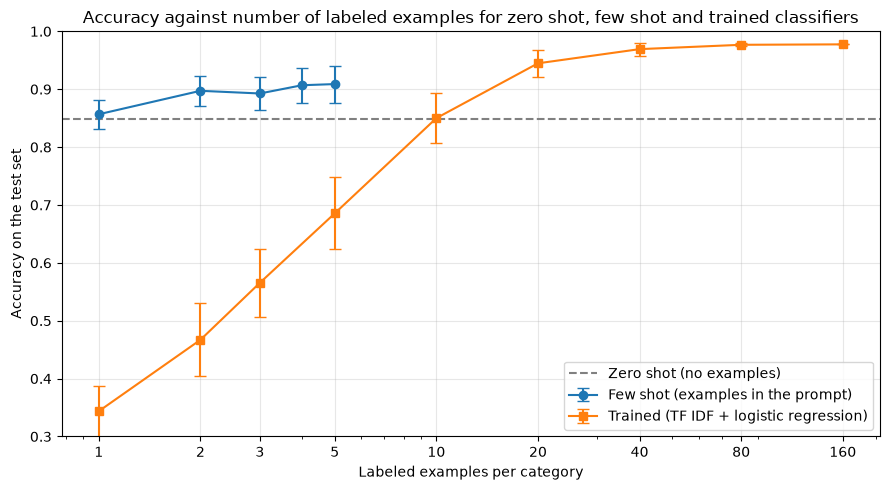

In [7]:
plt.figure(figsize=(9, 5))
plt.axhline(zero_acc, ls="--", color="gray", label="Zero shot (no examples)")
plt.errorbar(K_VALUES, few_accs.mean(axis=1), yerr=few_accs.std(axis=1), marker="o", capsize=4,
             label="Few shot (examples in the prompt)")
plt.errorbar(TRAIN_SIZES, trained_acc.mean(axis=1), yerr=trained_acc.std(axis=1), marker="s", capsize=4,
             label="Trained (TF IDF + logistic regression)")
plt.xscale("log")
plt.xticks(TRAIN_SIZES, [str(n) for n in TRAIN_SIZES])
plt.ylim(0.3, 1.0)
plt.xlabel("Labeled examples per category")
plt.ylabel("Accuracy on the test set")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.title("Accuracy against number of labeled examples for zero shot, few shot and trained classifiers")
plt.tight_layout()
plt.show()

## Step 8: Chart 2, where the few shot classifier gets confused
One accuracy number hides a lot. A confusion matrix puts the true labels down the side and the predicted labels across the top. Each row shows where the tickets of one true label ended up. I used three examples per label and pooled all 20 random draws, so each cell is the share of that row's tickets.

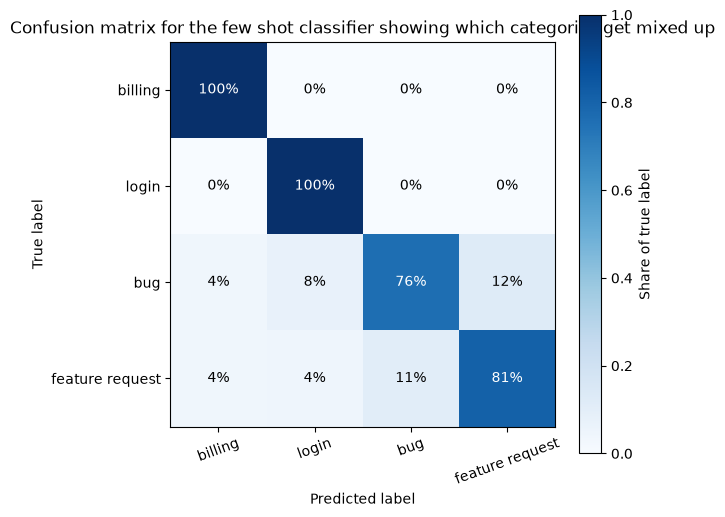

Few shot (3 per label): 12% of real bugs labeled as feature request, 11% of real feature requests labeled as bug


In [8]:
conf_rows = conf_k3 / conf_k3.sum(axis=1, keepdims=True)
plt.figure(figsize=(6.5, 5.5))
plt.imshow(conf_rows, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{conf_rows[i, j]:.0%}", ha="center", va="center",
                 color="white" if conf_rows[i, j] > 0.5 else "black")
plt.xticks(range(4), LABELS, rotation=20)
plt.yticks(range(4), LABELS)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.colorbar(label="Share of true label")
plt.title("Confusion matrix for the few shot classifier showing which categories get mixed up")
plt.tight_layout()
plt.show()

print(f"Few shot (3 per label): {conf_rows[2, 3]:.0%} of real bugs labeled as feature request, "
      f"{conf_rows[3, 2]:.0%} of real feature requests labeled as bug")

## Step 9: Chart 3, per category accuracy as the trained model gets more data
Now I split the trained model's accuracy by category. Billing and login should climb fast and flatten early, because their wording gives them away. Bug and feature request should keep improving for much longer, because the model needs many borderline tickets to learn how this team draws the line.

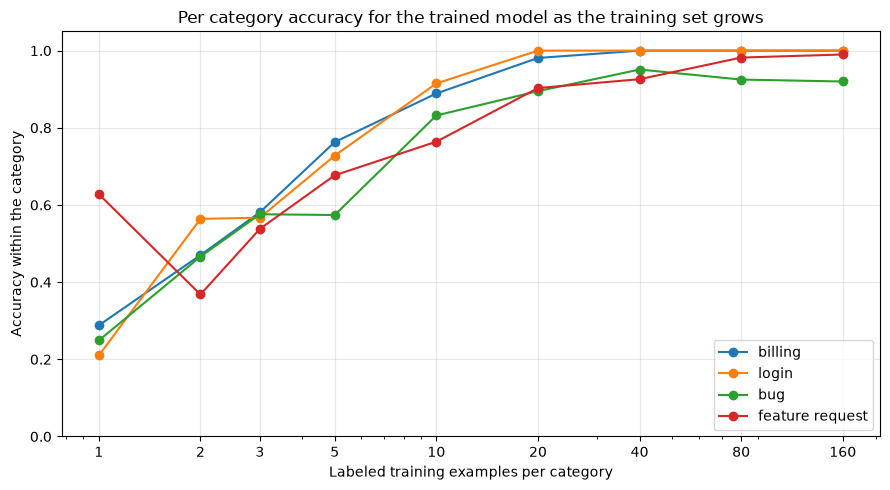

               billing  login    bug  feature request
1 per label      0.288  0.210  0.249            0.628
5 per label      0.763  0.728  0.574            0.677
160 per label    1.000  1.000  0.920            0.990


In [9]:
per_class_mean = trained_per_class.mean(axis=1)
plt.figure(figsize=(9, 5))
for c, lab in enumerate(LABELS):
    plt.plot(TRAIN_SIZES, per_class_mean[:, c], marker="o", label=lab)
plt.xscale("log")
plt.xticks(TRAIN_SIZES, [str(n) for n in TRAIN_SIZES])
plt.ylim(0, 1.05)
plt.xlabel("Labeled training examples per category")
plt.ylabel("Accuracy within the category")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.title("Per category accuracy for the trained model as the training set grows")
plt.tight_layout()
plt.show()

summary = pd.DataFrame(per_class_mean[[0, 3, -1]].round(3), columns=LABELS,
                       index=[f"{n} per label" for n in [TRAIN_SIZES[0], TRAIN_SIZES[3], TRAIN_SIZES[-1]]])
print(summary.to_string())

## What to take away
On this toy data, billing and login are nearly solved with zero or a few examples, because their words give them away. Bug versus feature request is where the few shot classifier stalls, and only the trained model, fed plenty of borderline tickets, learns how this team draws that line. Remember the data here is simulated and the LLM is a simple stand in, so treat the exact numbers as an illustration. The real test is to run the same comparison on 50 hand labeled tickets from your own inbox and look at the confusion matrix.